In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import dblquad
from matplotlib.lines import Line2D
from scipy.stats import multivariate_normal, norm

SEED = 2082172357 #seed previded by the RNG
rng = np.random.default_rng(SEED)
rng_step1 = rng.spawn(1)[0]
rng_step2 = rng.spawn(1)[0]
rng_step3 = rng.spawn(1)[0]
rng_step4 = rng.spawn(1)[0]
rng_step5 = rng.spawn(1)[0]
rng_step6 = rng.spawn(1)[0]
rng_step7 = rng.spawn(1)[0]
rng_step8 = rng.spawn(1)[0]

from mp3lib import sample_mean_cov, is_valid_covariance, gaussian_pdf, whitening_matrix, lmmse_weights
trap = getattr(np, "trapezoid", None) or np.trapz


### Validity of the Joint Density

The proposed joint density is

\[
f_{XY}(x,y)=x+y,
\qquad 0\leq x\leq 1,\quad 0\leq y\leq 1.
\]

First, \(f_{XY}(x,y)\geq 0\) throughout the unit square because both \(x\) and \(y\) are nonnegative.

Next, integrate over the entire support:

\[
\begin{aligned}
\int_0^1\int_0^1 (x+y)\,dy\,dx
&=\int_0^1\left[xy+\frac{y^2}{2}\right]_{0}^{1}dx\\
&=\int_0^1\left(x+\frac{1}{2}\right)dx\\
&=\left[\frac{x^2}{2}+\frac{x}{2}\right]_0^1\\
&=1.
\end{aligned}
\]

Since the density is nonnegative and integrates to 1, \(f_{XY}(x,y)\) is a valid joint probability density.

### Deriving the Marginal Densities

The marginal density of \(X\) is found by integrating the joint density over all possible values of \(Y\):

\[
\begin{aligned}
f_X(x)
&=\int_0^1 f_{XY}(x,y)\,dy\\
&=\int_0^1 (x+y)\,dy\\
&=\left[xy+\frac{y^2}{2}\right]_0^1\\
&=x+\frac{1}{2},
\qquad 0\leq x\leq 1.
\end{aligned}
\]

Therefore,

\[
f_X(x)=
\begin{cases}
x+\frac{1}{2}, & 0\leq x\leq 1,\\
0, & \text{otherwise}.
\end{cases}
\]

The marginal density of \(Y\) is found by integrating the joint density over all possible values of \(X\):

\[
\begin{aligned}
f_Y(y)
&=\int_0^1 f_{XY}(x,y)\,dx\\
&=\int_0^1 (x+y)\,dx\\
&=\left[\frac{x^2}{2}+xy\right]_0^1\\
&=y+\frac{1}{2},
\qquad 0\leq y\leq 1.
\end{aligned}
\]

Therefore,

\[
f_Y(y)=
\begin{cases}
y+\frac{1}{2}, & 0\leq y\leq 1,\\
0, & \text{otherwise}.
\end{cases}
\]

Numerical integral of joint density = 1.00000000
Maximum error in f_X(x) = 2.22044605e-16
Maximum error in f_Y(y) = 8.88178420e-16
f_X(0.3) = 0.80000000
f_Y|X(0.3|0.3) = 0.75000000
Integral of conditional density = 1.00000000

Numerical quadrature values:
E[X] = 0.58333333
E[Y] = 0.58333333
E[XY] = 0.33333333
Var(X) = 0.07638889
Var(Y) = 0.07638889
Cov(X,Y) = -0.00694444
Correlation = -0.09090909

Number of accepted samples = 1,000,000
Number of proposed samples = 2,200,000
Acceptance rate = 0.50006318

Rejection-sampling results:
E[X]          : estimate = 0.58335089, exact = 0.58333333, difference = 1.75576173e-05, SE = 2.65272657e-04
E[Y]          : estimate = 0.58354161, exact = 0.58333333, difference = 2.08279570e-04, SE = 2.62972992e-04
E[XY]         : estimate = 0.33341825, exact = 0.33333333, difference = 8.49121844e-05, SE = 2.37179142e-04
Var(X)        : estimate = 0.07642236, exact = 0.07638889, difference = 3.34727946e-05, SE = 6.72956144e-05
Var(Y)        : estimate = 0.07

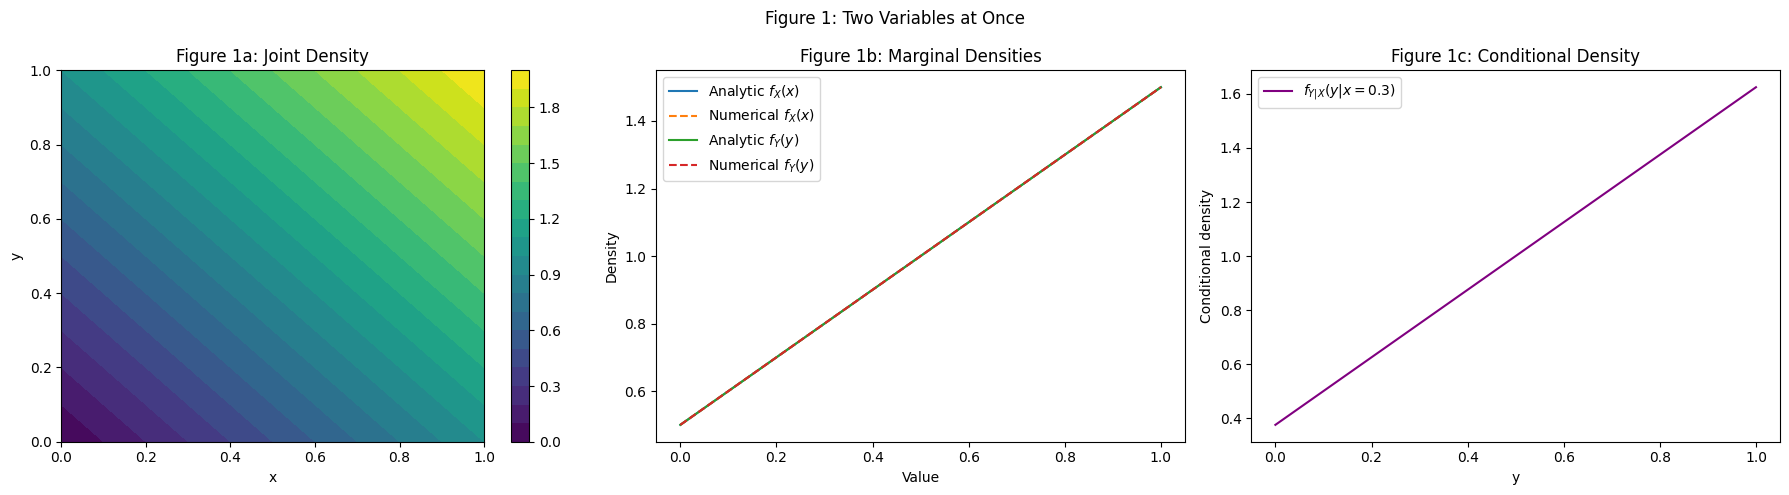

Summary of Figure 1:
The joint density increases toward the upper-right because f_XY(x,y) = x + y.
The analytical and numerical marginal densities overlap, showing that the numerical integration is accurate.
The conditional density f_Y|X(y|x = 0.3) increases linearly with y, and
the conditional density integrates to 1, as required for a valid probability density.
The density has diagonal contours, so after accounting for the marginals, larger values of X are paired with slightly smaller values of Y.
This causes a weak negative covariance and makes X and Y pull against each other slightly.


In [27]:
# Step 1: Two variables at once

# Joint density: f_XY(x,y) = x + y, 0 <= x <= 1, 0 <= y <= 1

def joint_pdf(x, y):
    inside = (0 <= x) & (x <= 1) & (0 <= y) & (y <= 1)
    return np.where(inside, x + y, 0.0)


def marginal_x_analytic(x):
    return np.where((0 <= x) & (x <= 1), x + 0.5, 0.0)


def marginal_y_analytic(y):
    return np.where((0 <= y) & (y <= 1), y + 0.5, 0.0)


def conditional_y_given_x(y, x_value):
    return np.where(
        (0 <= y) & (y <= 1),
        (x_value + y) / (x_value + 0.5),
        0.0
    )


# density 
total_probability = dblquad(
    lambda y, x: joint_pdf(x, y),
    0, 1,
    lambda x: 0,
    lambda x: 1
)[0]

print(f"Numerical integral of joint density = {total_probability:.8f}")


x_grid = np.linspace(0, 1, 501)
y_grid = np.linspace(0, 1, 501)

joint_grid = joint_pdf(
    x_grid[:, None],
    y_grid[None, :]
)

marginal_x_numerical = np.trapezoid(
    joint_grid,
    y_grid,
    axis=1
)

marginal_y_numerical = np.trapezoid(
    joint_grid,
    x_grid,
    axis=0
)

print(
    f"Maximum error in f_X(x) = "
    f"{np.max(np.abs(marginal_x_numerical - marginal_x_analytic(x_grid))):.8e}"
)

print(
    f"Maximum error in f_Y(y) = "
    f"{np.max(np.abs(marginal_y_numerical - marginal_y_analytic(y_grid))):.8e}"
)


# ------------------------------------------------------------
# Conditional density
# ------------------------------------------------------------

x_value = 0.3

conditional_density = conditional_y_given_x(
    y_grid,
    x_value
)

print(
    f"f_X(0.3) = "
    f"{marginal_x_analytic(np.array([0.3]))[0]:.8f}"
)

print(
    f"f_Y|X(0.3|0.3) = "
    f"{conditional_y_given_x(np.array([0.3]), x_value)[0]:.8f}"
)

print(
    f"Integral of conditional density = "
    f"{np.trapezoid(conditional_density, y_grid):.8f}"
)


# ------------------------------------------------------------
# Analytical and numerical moments
# ------------------------------------------------------------

exact_statistics = np.array([
    7 / 12,       # E[X]
    7 / 12,       # E[Y]
    1 / 3,        # E[XY]
    11 / 144,     # Var(X)
    11 / 144,     # Var(Y)
    -1 / 144,     # Cov(X,Y)
    -1 / 11       # Correlation
])

labels = [
    "E[X]",
    "E[Y]",
    "E[XY]",
    "Var(X)",
    "Var(Y)",
    "Cov(X,Y)",
    "Correlation"
]


def integrate_joint(function):
    return dblquad(
        lambda y, x: function(x, y) * joint_pdf(x, y),
        0, 1,
        lambda x: 0,
        lambda x: 1
    )[0]


EX = integrate_joint(lambda x, y: x)
EY = integrate_joint(lambda x, y: y)
EXY = integrate_joint(lambda x, y: x * y)

EX2 = integrate_joint(lambda x, y: x**2)
EY2 = integrate_joint(lambda x, y: y**2)

VAR_X = EX2 - EX**2
VAR_Y = EY2 - EY**2
COV_XY = EXY - EX * EY
CORR_XY = COV_XY / np.sqrt(VAR_X * VAR_Y)

numerical_statistics = np.array([
    EX,
    EY,
    EXY,
    VAR_X,
    VAR_Y,
    COV_XY,
    CORR_XY
])

print("\nNumerical quadrature values:")

for label, value in zip(labels, numerical_statistics):
    print(f"{label} = {value:.8f}")


# pt 5 - rejection sampling

number_of_samples = 1_000_000
accepted_points = []
number_proposed = 0
number_accepted = 0

while number_accepted < number_of_samples:

    batch_size = 200_000

    proposal = rng_step1.random((batch_size, 2))
    x_proposal = proposal[:, 0]
    y_proposal = proposal[:, 1]

    acceptance_probability = (
        x_proposal + y_proposal
    ) / 2

    accepted = (
        rng_step1.random(batch_size)
        < acceptance_probability
    )

    accepted_batch = proposal[accepted]

    accepted_points.append(accepted_batch)
    number_accepted += accepted_batch.shape[0]
    number_proposed += batch_size

samples = np.vstack(accepted_points)[:number_of_samples]

print(
    f"\nNumber of accepted samples = "
    f"{samples.shape[0]:,}"
)

print(
    f"Number of proposed samples = "
    f"{number_proposed:,}"
)

print(
    f"Acceptance rate = "
    f"{number_accepted / number_proposed:.8f}"
)


def calculate_statistics(data):
    x = data[:, 0]
    y = data[:, 1]

    return np.array([
        np.mean(x),
        np.mean(y),
        np.mean(x * y),
        np.var(x, ddof=1),
        np.var(y, ddof=1),
        np.cov(x, y, ddof=1)[0, 1],
        np.corrcoef(x, y)[0, 1]
    ])


sample_statistics = calculate_statistics(samples)

number_of_batches = 100
batches = np.array_split(samples, number_of_batches)

batch_statistics = np.array([
    calculate_statistics(batch)
    for batch in batches
])

standard_errors = (
    np.std(batch_statistics, axis=0, ddof=1)
    / np.sqrt(number_of_batches)
)

print("\nRejection-sampling results:")

for label, estimate, exact, standard_error in zip(
    labels,
    sample_statistics,
    exact_statistics,
    standard_errors
):
    print(
        f"{label:14s}: "
        f"estimate = {estimate:.8f}, "
        f"exact = {exact:.8f}, "
        f"difference = {estimate - exact:.8e}, "
        f"SE = {standard_error:.8e}"
    )


X_plot, Y_plot = np.meshgrid(x_grid, y_grid)
Z_plot = joint_pdf(X_plot, Y_plot)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

# Joint density
contour = axes[0].contourf(
    X_plot,
    Y_plot,
    Z_plot,
    levels=20,
    cmap="viridis"
)

fig.colorbar(contour, ax=axes[0])
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].set_title("Figure 1a: Joint Density")


# Marginal densities
axes[1].plot(
    x_grid,
    marginal_x_analytic(x_grid),
    label="Analytic $f_X(x)$"
)

axes[1].plot(
    x_grid,
    marginal_x_numerical,
    "--",
    label="Numerical $f_X(x)$"
)

axes[1].plot(
    y_grid,
    marginal_y_analytic(y_grid),
    label="Analytic $f_Y(y)$"
)

axes[1].plot(
    y_grid,
    marginal_y_numerical,
    "--",
    label="Numerical $f_Y(y)$"
)

axes[1].set_xlabel("Value")
axes[1].set_ylabel("Density")
axes[1].set_title("Figure 1b: Marginal Densities")
axes[1].legend()


# Conditional density
axes[2].plot(
    y_grid,
    conditional_density,
    color="purple",
    label="$f_{Y|X}(y|x=0.3)$"
)

axes[2].set_xlabel("y")
axes[2].set_ylabel("Conditional density")
axes[2].set_title("Figure 1c: Conditional Density")
axes[2].legend()

plt.suptitle("Figure 1: Two Variables at Once")
plt.tight_layout()
plt.show()


# Interpretation
print(f"Summary of Figure 1:")
print(f"The joint density increases toward the upper-right because f_XY(x,y) = x + y.")
print(f"The analytical and numerical marginal densities overlap, showing that the numerical integration is accurate.")
print(f"The conditional density f_Y|X(y|x = 0.3) increases linearly with y, and")
print(f"the conditional density integrates to 1, as required for a valid probability density.")
print(f"The density has diagonal contours, so after accounting for the marginals, larger values of X are paired with slightly smaller values of Y.")
print(f"This causes a weak negative covariance and makes X and Y pull against each other slightly.")

### Covariance of \(X\) and \(Y=X^2\)

Let

$$
X \sim \operatorname{Uniform}(-1,1),
\qquad
Y=X^2.
$$

The probability density of \(X\) is

$$
f_X(x)=\frac{1}{2},
\qquad -1\leq x\leq 1.
$$

First,

$$
E[X]
=
\int_{-1}^{1} x\frac{1}{2}\,dx
=
0.
$$

Also,

$$
E[Y]
=
E[X^2]
=
\int_{-1}^{1} x^2\frac{1}{2}\,dx
=
\frac{1}{3}.
$$

Finally,

$$
E[XY]
=
E[X^3]
=
\int_{-1}^{1} x^3\frac{1}{2}\,dx
=
0.
$$

The covariance is therefore

$$
\begin{aligned}
\operatorname{Cov}(X,Y)
&=E[XY]-E[X]E[Y]\\
&=0-(0)\left(\frac{1}{3}\right)\\
&=0.
\end{aligned}
$$

Thus, \(X\) and \(Y=X^2\) are uncorrelated, even though \(Y\) is completely determined by \(X\).

Analytical Cov(X,Y) = 0.00000000
Sample correlation = -2.87385721e-05
Correlation standard error = 4.05824201e-04
Correlation measures only linear dependence.
For Y = X^2, the relationship is nonlinear, so positive and negative X values cancel and produce zero correlation.
However, Y is still completely determined by X, so the variables are dependent.
Maximum binned conditional variance = 1.31644232e-04
Mean binned conditional variance = 4.44695484e-05


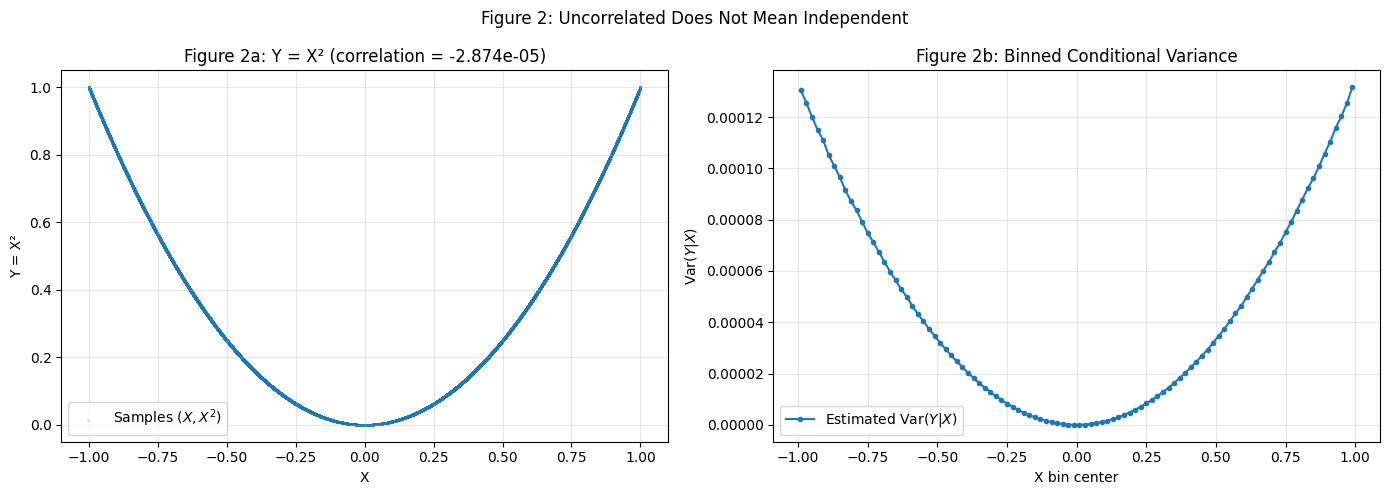

Figure 2 summary:
The scatter plot shows the nonlinear relationship Y = X², even though the correlation is nearly zero.
The small binned conditional variances show that knowing X almost completely determines Y.

Gaussian joint/product Frobenius difference = 3.59280719e-02

For jointly Gaussian variables, zero correlation causes the joint density to factor into the marginal densities.
Therefore, uncorrelated jointly Gaussian variables are independent.
In general, nonlinear dependence can exist even when correlation is zero.
This makes the Gaussian assumption important because many engineering methods rely only on means and covariances.


In [28]:
# Step 2: Uncorrelated does not mean independent

number_of_samples_step2 = 10_000_000

# X is Uniform(-1,1), and Y is completely determined by X
x_step2 = rng_step2.uniform(
    -1,
    1,
    number_of_samples_step2
)

y_step2 = x_step2**2


# ------------------------------------------------------------
# Covariance and correlation
# ------------------------------------------------------------

print(f"Analytical Cov(X,Y) = {0.0:.8f}")

sample_correlation_step2 = np.corrcoef(
    x_step2,
    y_step2
)[0, 1]

# Estimate the correlation standard error using batches
number_of_batches_step2 = 100

batch_correlations_step2 = []

for x_batch, y_batch in zip(
    np.array_split(x_step2, number_of_batches_step2),
    np.array_split(y_step2, number_of_batches_step2)
):
    batch_correlations_step2.append(
        np.corrcoef(x_batch, y_batch)[0, 1]
    )

correlation_standard_error_step2 = (
    np.std(batch_correlations_step2, ddof=1)
    / np.sqrt(number_of_batches_step2)
)

print(
    f"Sample correlation = "
    f"{sample_correlation_step2:.8e}"
)

print(
    f"Correlation standard error = "
    f"{correlation_standard_error_step2:.8e}"
)

print(f"Correlation measures only linear dependence.")
print(f"For Y = X^2, the relationship is nonlinear, so positive and negative X values cancel and produce zero correlation.")
print(f"However, Y is still completely determined by X, so the variables are dependent.")


# ------------------------------------------------------------
# Binned conditional variance
# ------------------------------------------------------------

number_of_bins_step2 = 100

bin_edges_step2 = np.linspace(
    -1,
    1,
    number_of_bins_step2 + 1
)

bin_centers_step2 = (
    bin_edges_step2[:-1]
    + bin_edges_step2[1:]
) / 2

conditional_variances_step2 = []

for lower_edge, upper_edge in zip(
    bin_edges_step2[:-1],
    bin_edges_step2[1:]
):
    in_bin = (
        (x_step2 >= lower_edge)
        & (x_step2 < upper_edge)
    )

    conditional_variances_step2.append(
        np.var(y_step2[in_bin], ddof=1)
    )

conditional_variances_step2 = np.array(
    conditional_variances_step2
)

print(
    f"Maximum binned conditional variance = "
    f"{np.max(conditional_variances_step2):.8e}"
)

print(
    f"Mean binned conditional variance = "
    f"{np.mean(conditional_variances_step2):.8e}"
)


# ------------------------------------------------------------
# Figure 2
# ------------------------------------------------------------

plot_size_step2 = 100_000

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

axes[0].scatter(
    x_step2[:plot_size_step2],
    y_step2[:plot_size_step2],
    s=1,
    alpha=0.2,
    label=r"Samples $(X,X^2)$"
)

axes[0].set_xlabel("X")
axes[0].set_ylabel("Y = X²")

axes[0].set_title(
    f"Figure 2a: Y = X² "
    f"(correlation = {sample_correlation_step2:.3e})"
)

axes[0].legend()
axes[0].grid(alpha=0.3)


axes[1].plot(
    bin_centers_step2,
    conditional_variances_step2,
    "o-",
    markersize=3,
    label=r"Estimated $\operatorname{Var}(Y|X)$"
)

axes[1].set_xlabel("X bin center")
axes[1].set_ylabel(r"$\operatorname{Var}(Y|X)$")
axes[1].set_title("Figure 2b: Binned Conditional Variance")

axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle("Figure 2: Uncorrelated Does Not Mean Independent")
plt.tight_layout()
plt.show()


print(f"Figure 2 summary:")
print(f"The scatter plot shows the nonlinear relationship Y = X², even though the correlation is nearly zero.")
print(f"The small binned conditional variances show that knowing X almost completely determines Y.\n")


# ------------------------------------------------------------
# Gaussian comparison
# ------------------------------------------------------------

gaussian_samples_step2 = rng_step2.standard_normal(
    (1_000_000, 2)
)

gaussian_x_step2 = gaussian_samples_step2[:, 0]
gaussian_y_step2 = gaussian_samples_step2[:, 1]

histogram_edges_step2 = np.linspace(-4, 4, 51)

joint_density_step2, _, _ = np.histogram2d(
    gaussian_x_step2,
    gaussian_y_step2,
    bins=[histogram_edges_step2, histogram_edges_step2],
    density=True
)

x_density_step2, _ = np.histogram(
    gaussian_x_step2,
    bins=histogram_edges_step2,
    density=True
)

y_density_step2, _ = np.histogram(
    gaussian_y_step2,
    bins=histogram_edges_step2,
    density=True
)

product_of_marginals_step2 = np.outer(
    x_density_step2,
    y_density_step2
)

gaussian_difference_step2 = np.linalg.norm(
    joint_density_step2
    - product_of_marginals_step2
)

print(
    f"Gaussian joint/product Frobenius difference = "
    f"{gaussian_difference_step2:.8e}"
)


# Step 6 explanation

print(f"\nFor jointly Gaussian variables, zero correlation causes the joint density to factor into the marginal densities.")
print(f"Therefore, uncorrelated jointly Gaussian variables are independent.")
print(f"In general, nonlinear dependence can exist even when correlation is zero.")
print(f"This makes the Gaussian assumption important because many engineering methods rely only on means and covariances.")

Sigma is symmetric? True
Sigma is valid? True
Eigenvalues of Sigma: [1.26487889 1.78819531 3.09808432 7.84884147]
Determinant of Sigma: 55.0000
Non-symmetric matrix is valid? False
Matrix with a negative eigenvalue is valid? False

Single-draw errors:
N = 100, Frobenius error = 0.624151
N = 1,000, Frobenius error = 0.485810
N = 10,000, Frobenius error = 0.127057
N = 100,000, Frobenius error = 0.039803
N = 1,000,000, Frobenius error = 0.016319

Averaged errors:
N = 100, average error = 1.581010, SE = 0.037133, error*sqrt(N) = 15.810099
N = 1,000, average error = 0.519180, SE = 0.011916, error*sqrt(N) = 16.417905
N = 10,000, average error = 0.148900, SE = 0.005162, error*sqrt(N) = 14.889955
N = 100,000, average error = 0.048895, SE = 0.003656, error*sqrt(N) = 15.461875
N = 1,000,000, average error = 0.015469, SE = 0.001624, error*sqrt(N) = 15.469043

Fitted slope = -0.5045
Expected slope = -0.5000


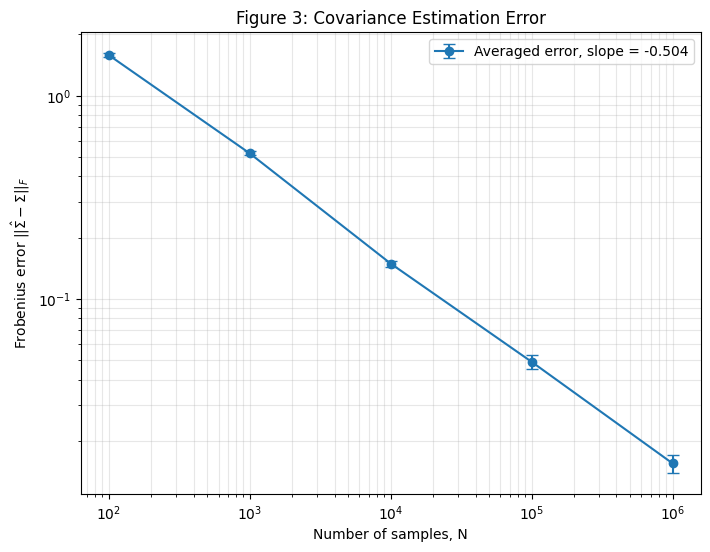


Number of free covariance parameters:
d = 4: 10
d = 100: 5050
Estimated samples needed for d = 100: 5,050,000
A radar with 100 array elements needs to estimate 5,050 covariance parameters.
This requires many snapshots, and a poor estimate can cause inaccurate beamforming and unstable detection.
One solution is to use shrinkage or diagonal loading, which improves the covariance estimate when data is limited.


In [29]:
# Step 3: The covariance matrix and how well you can estimate it

# 1 - Confirm sigma is a valid covariance matrix
Sigma = np.array([
    [4, 2, 1, 0],
    [2, 5, 2, 1],
    [1, 2, 3, 1],
    [0, 1, 1, 2]
], dtype=float)

mean = np.zeros(4)


eigenvalues = np.linalg.eigh(Sigma)[0]
determinant = np.linalg.det(Sigma)

non_symmetric = np.array([
    [1, 2],
    [0, 1]
])

negative_eigenvalue = np.array([
    [1, 0],
    [0, -1]
])

print(f"Sigma is symmetric? {np.allclose(Sigma, Sigma.T)}")
print(f"Sigma is valid? {is_valid_covariance(Sigma)}")
print(f"Eigenvalues of Sigma: {eigenvalues}")
print(f"Determinant of Sigma: {determinant:.4f}")

print(
    f"Non-symmetric matrix is valid? "
    f"{is_valid_covariance(non_symmetric)}"
)

print(
    f"Matrix with a negative eigenvalue is valid? "
    f"{is_valid_covariance(negative_eigenvalue)}"
)


# Step 2 - generate samples with this covariance
sample_sizes = np.array([
    10**2,
    10**3,
    10**4,
    10**5,
    10**6
])

single_errors = []

for N in sample_sizes:
    samples = rng_step3.multivariate_normal(
        mean,
        Sigma,
        size=N
    )

    _, estimated_covariance = sample_mean_cov(samples)

    error = np.linalg.norm(
        estimated_covariance - Sigma,
        ord="fro"
    )

    single_errors.append(error)

single_errors = np.array(single_errors)

print("\nSingle-draw errors:")

for N, error in zip(sample_sizes, single_errors):
    print(
        f"N = {N:,}, "
        f"Frobenius error = {error:.6f}"
    )


# Step 3 - repeated many times

repetitions = [
    200,
    200,
    100,
    30,
    10
]

average_errors = []
standard_errors = []

for N, number_of_repetitions in zip(
    sample_sizes,
    repetitions
):
    errors = []

    for repetition in range(number_of_repetitions):
        samples = rng_step3.multivariate_normal(
            mean,
            Sigma,
            size=N
        )

        _, estimated_covariance = sample_mean_cov(samples)

        error = np.linalg.norm(
            estimated_covariance - Sigma,
            ord="fro"
        )

        errors.append(error)

    errors = np.array(errors)

    average_errors.append(
        np.mean(errors)
    )

    standard_errors.append(
        np.std(errors, ddof=1)
        / np.sqrt(number_of_repetitions)
    )

average_errors = np.array(average_errors)
standard_errors = np.array(standard_errors)


# Step 4 - repeat and plot 

slope, intercept = np.polyfit(
    np.log10(sample_sizes),
    np.log10(average_errors),
    1
)

scaled_errors = average_errors * np.sqrt(sample_sizes)

print("\nAveraged errors:")

for N, average_error, standard_error, scaled_error in zip(
    sample_sizes,
    average_errors,
    standard_errors,
    scaled_errors
):
    print(
        f"N = {N:,}, "
        f"average error = {average_error:.6f}, "
        f"SE = {standard_error:.6f}, "
        f"error*sqrt(N) = {scaled_error:.6f}"
    )

print(f"\nFitted slope = {slope:.4f}")
print(f"Expected slope = {-0.5:.4f}")


plt.figure(figsize=(8, 6))

plt.errorbar(
    sample_sizes,
    average_errors,
    yerr=standard_errors,
    fmt="o-",
    capsize=4,
    label=f"Averaged error, slope = {slope:.3f}"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Number of samples, N")
plt.ylabel(r"Frobenius error $||\hat{\Sigma}-\Sigma||_F$")
plt.title("Figure 3: Covariance Estimation Error")
plt.legend()
plt.grid(True, which="both", alpha=0.3)

plt.show()


#step 5 - number of free covariance parameters

parameters_d4 = 4 * (4 + 1) // 2
parameters_d100 = 100 * (100 + 1) // 2

estimated_samples_d100 = (
    10**4 * parameters_d100 / parameters_d4
)

print("\nNumber of free covariance parameters:")
print(f"d = 4: {parameters_d4}")
print(f"d = 100: {parameters_d100}")

print(
    f"Estimated samples needed for d = 100: "
    f"{estimated_samples_d100:,.0f}"
)

# Step 6 question
print(f"A radar with 100 array elements needs to estimate 5,050 covariance parameters.")
print(f"This requires many snapshots, and a poor estimate can cause inaccurate beamforming and unstable detection.")
print(f"One solution is to use shrinkage or diagonal loading, which improves the covariance estimate when data is limited.")

# Step 4: Linear Transformations of Random Vectors

## Transformation rules

Let $x$ be a random vector with mean $\mu_x$ and covariance $\Sigma_x$, and let $y = Ax + b$ with $A$ and $b$ fixed.

**Mean.** Expectation is linear, and constants come out of it:
$$\mu_y = E[Ax + b] = A\,E[x] + b = A\mu_x + b.$$

**Covariance.** Three lines:

1. Subtract the mean. The shift $b$ cancels: $\;y - \mu_y = (Ax + b) - (A\mu_x + b) = A(x - \mu_x).$
2. Insert into the definition: $\;\Sigma_y = E\big[(y-\mu_y)(y-\mu_y)^T\big] = E\big[A(x-\mu_x)(x-\mu_x)^T A^T\big].$
3. $A$ and $A^T$ are constants, so they leave the expectation:
$$\Sigma_y = A\,E\big[(x-\mu_x)(x-\mu_x)^T\big]\,A^T = A\Sigma_x A^T.$$

Neither rule uses Gaussianity.

## Hand calculation and simulation check

Given $\mu_x = [1,\,-2]^T$, $\Sigma_x = \begin{bmatrix}4&2\\2&4\end{bmatrix}$, $A = \begin{bmatrix}1&2\\0&1\\1&-1\end{bmatrix}$, $b = 0$:
$$\mu_y = A\mu_x = \begin{bmatrix}1\cdot 1 + 2\cdot(-2)\\ 0\cdot 1 + 1\cdot(-2)\\ 1\cdot 1 - 1\cdot(-2)\end{bmatrix} = \begin{bmatrix}-3\\-2\\3\end{bmatrix}.$$
$$\Sigma_x A^T = \begin{bmatrix}4&2\\2&4\end{bmatrix}\begin{bmatrix}1&0&1\\2&1&-1\end{bmatrix} = \begin{bmatrix}8&2&2\\10&4&-2\end{bmatrix},$$
$$\Sigma_y = A\,(\Sigma_x A^T) = \begin{bmatrix}8+20 & 2+8 & 2-4\\ 10 & 4 & -2\\ 8-10 & 2-4 & 2+2\end{bmatrix} = \begin{bmatrix}28&10&-2\\10&4&-2\\-2&-2&4\end{bmatrix}.$$

The simulation draws $x$ as Gaussian for convenience of sampling. Standard errors are estimated from the data: $s_i/\sqrt N$ for a mean, and the standard deviation of the per-sample products $(y_i-\bar y_i)(y_j-\bar y_j)$ divided by $\sqrt N$ for a covariance entry.

**Simulation check.** The simulated mean and covariance agree with $\mu_y = [-3,-2,3]^T$ and $A\Sigma_xA^T$ to within sampling error. The largest z-score over the three means and nine covariance entries is **[max |z| from output]**, and the Frobenius norm of the covariance difference is **[value]** at $N = 10^6$.

## Rank of $\Sigma_y$

$\Sigma_y$ is $3\times 3$, but $\operatorname{rank}(A\Sigma_xA^T) \le \operatorname{rank}(A) = 2$, so it must be singular. To find the flat direction, solve $n^TA = 0$: the columns of $A$ are $(1,0,1)$ and $(2,1,-1)$, giving $n_1 + n_3 = 0$ and $2n_1 + n_2 - n_3 = 0$, so $n \propto (-1, 3, 1)$. Then $n^Ty = n^TAx = 0$ for every sample.

The smallest eigenvalue of $\Sigma_y$ is **[value]**, which is rounding level. The reason is that $y$ is built from only two random inputs, so it cannot vary in all three directions. Geometrically, every sample lies on the plane $-y_1 + 3y_2 + y_3 = 0$, which passes through the origin and through $\mu_y$ since $b=0$. The largest $|n^Ty|$ over $10^6$ samples is **[value]**, and the eigenvector of the zero eigenvalue is the plane's normal ($|\cos|$ with the hand value = **[value]**).

## Rank-deficient $A$

With $A = \begin{bmatrix}1&1\\2&2\end{bmatrix} = u\,\mathbf 1^T$, $u = [1,2]^T$, $\mathbf 1 = [1,1]^T$:
$$\mu_y = \begin{bmatrix}-1\\-2\end{bmatrix},\qquad \Sigma_y = u\,(\mathbf 1^T\Sigma_x\mathbf 1)\,u^T = 12\begin{bmatrix}1&2\\2&4\end{bmatrix} = \begin{bmatrix}12&24\\24&48\end{bmatrix},$$
since $\mathbf 1^T\Sigma_x\mathbf 1 = 4 + 4 + 2\cdot 2 = 12$. This has rank 1.

## Singular covariance and the Gaussian density

The density needs $\Sigma^{-1}$ and $1/\sqrt{\det\Sigma}$. The determinant printed above is zero (or at rounding level), so $\Sigma^{-1}$ does not exist and the normalizing constant is infinite; `solve` raises a singular-matrix error. This matches the line above: all the probability sits on a line, which has zero area in the plane, so there is no ordinary density.

hand mean matches A mu_x: True
hand covariance matches A Sx A^T: True

analytic mean  = [-3. -2.  3.]
simulated mean = [-3.0083 -2.003   3.0008]
difference     = [-0.0083 -0.003   0.0008]
standard error = [0.0053 0.002  0.002 ]
z-scores       = [-1.576  -1.5221  0.3966]

analytic covariance =
[[28. 10. -2.]
 [10.  4. -2.]
 [-2. -2.  4.]]
simulated covariance =
[[27.9622  9.9867 -1.9979]
 [ 9.9867  3.995  -1.9982]
 [-1.9979 -1.9982  3.9968]]
difference =
[[-0.0378 -0.0133  0.0021]
 [-0.0133 -0.005   0.0018]
 [ 0.0021  0.0018 -0.0032]]
standard errors =
[[0.0395 0.0145 0.0107]
 [0.0145 0.0056 0.0045]
 [0.0107 0.0045 0.0057]]
z-scores =
[[-0.956  -0.9157  0.1991]
 [-0.9157 -0.8905  0.3971]
 [ 0.1991  0.3971 -0.5615]]

max |z| over means and covariance entries = 1.58
Frobenius norm of covariance difference = 0.0428

rank(Sigma_y) = 2
eigenvalues of Sigma_y = [5.01865857e-16 4.14359354e+00 3.18564065e+01]
n^T A = [0. 0.]
|cos| between eigh null eigenvector and hand n = 1.000000
max |n^T y| 

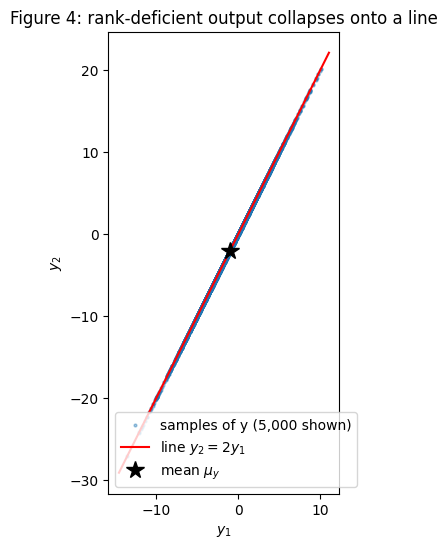


det(Sigma_y) for the rank-deficient A = 0.000e+00
eigenvalues = [ 0. 60.]
np.linalg.solve(Sigma_y, v): LinAlgError: Singular matrix
gaussian_pdf: ValueError: Sigma must be positive definite


In [30]:
# STEP 4: Linear Transformations of Random Vector

# ---- hand results vs simulation (first A) ----
mu_x = np.array([1.0, -2.0])
Sx = np.array([[4.0, 2.0], [2.0, 4.0]])
A = np.array([[1.0, 2.0], [0.0, 1.0], [1.0, -1.0]])

mu_y_hand = np.array([-3.0, -2.0, 3.0])
Sy_hand = np.array([[28.0, 10.0, -2.0], [10.0, 4.0, -2.0], [-2.0, -2.0, 4.0]])

mu_y = A @ mu_x
Sy = A @ Sx @ A.T
print(f"hand mean matches A mu_x: {np.allclose(mu_y, mu_y_hand)}")
print(f"hand covariance matches A Sx A^T: {np.allclose(Sy, Sy_hand)}")

N4 = 10**6
X = rng_step4.multivariate_normal(mu_x, Sx, size=N4)
Y = X @ A.T

mu_hat = Y.mean(axis=0)
Yc = Y - mu_hat
S_hat = (Yc.T @ Yc) / (N4 - 1)
se_mu = Y.std(axis=0, ddof=1) / np.sqrt(N4)
se_S = np.empty((3, 3))
for i in range(3):
    for j in range(3):
        se_S[i, j] = np.std(Yc[:, i] * Yc[:, j], ddof=1) / np.sqrt(N4)

z_mu = (mu_hat - mu_y) / se_mu
z_S = (S_hat - Sy) / se_S
fro_diff4 = np.linalg.norm(S_hat - Sy)

with np.printoptions(precision=4, suppress=True):
    print(f"\nanalytic mean  = {mu_y}")
    print(f"simulated mean = {mu_hat}")
    print(f"difference     = {mu_hat - mu_y}")
    print(f"standard error = {se_mu}")
    print(f"z-scores       = {z_mu}")
    print(f"\nanalytic covariance =\n{Sy}")
    print(f"simulated covariance =\n{S_hat}")
    print(f"difference =\n{S_hat - Sy}")
    print(f"standard errors =\n{se_S}")
    print(f"z-scores =\n{z_S}")
print(f"\nmax |z| over means and covariance entries = {max(np.abs(z_mu).max(), np.abs(z_S).max()):.2f}")
print(f"Frobenius norm of covariance difference = {fro_diff4:.4f}")

# ---- rank of Sigma_y ----
rank_y = np.linalg.matrix_rank(Sy)
evals_y, evecs_y = np.linalg.eigh(Sy)
n_vec = np.array([-1.0, 3.0, 1.0]) / np.sqrt(11.0)
cos_align = abs(evecs_y[:, 0] @ n_vec)
max_plane_resid = np.max(np.abs(Y @ n_vec))
print(f"\nrank(Sigma_y) = {rank_y}")
print(f"eigenvalues of Sigma_y = {evals_y}")
print(f"n^T A = {n_vec @ A}")
print(f"|cos| between eigh null eigenvector and hand n = {cos_align:.6f}")
print(f"max |n^T y| over {N4:,} samples = {max_plane_resid:.2e}")

# ---- rank-deficient A ----
A2 = np.array([[1.0, 1.0], [2.0, 2.0]])
mu_y2 = A2 @ mu_x
Sy2 = A2 @ Sx @ A2.T
Y2 = rng_step4.multivariate_normal(mu_x, Sx, size=N4) @ A2.T

mu_hat2 = Y2.mean(axis=0)
S_hat2 = np.cov(Y2, rowvar=False)
rank_y2 = np.linalg.matrix_rank(Sy2)
max_line_resid = np.max(np.abs(Y2[:, 1] - 2.0 * Y2[:, 0]))
fro_diff4b = np.linalg.norm(S_hat2 - Sy2)

with np.printoptions(precision=4, suppress=True):
    print(f"\nmu_y  = {mu_y2}   (simulated {mu_hat2})")
    print(f"Sigma_y =\n{Sy2}")
    print(f"simulated Sigma_y =\n{S_hat2}")
print(f"rank(Sigma_y) = {rank_y2}")
print(f"Frobenius norm of covariance difference = {fro_diff4b:.4f}")
print(f"max |y2 - 2 y1| over {N4:,} samples = {max_line_resid:.2e}")

# ---- Figure 4 ----
n_plot = 5000
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(Y2[:n_plot, 0], Y2[:n_plot, 1], s=4, alpha=0.4, label=f"samples of y ({n_plot:,} shown)")
t_line = np.array([Y2[:n_plot, 0].min() - 1.0, Y2[:n_plot, 0].max() + 1.0])
ax.plot(t_line, 2.0 * t_line, "r-", lw=1.5, label=r"line $y_2 = 2y_1$")
ax.plot(*mu_y2, "k*", ms=13, label=r"mean $\mu_y$")
ax.set_aspect("equal")
ax.set_xlabel("$y_1$")
ax.set_ylabel("$y_2$")
ax.set_title("Figure 4: rank-deficient output collapses onto a line")
ax.legend()
plt.show()

# ---- singular covariance breaks the density ----
det_Sy2 = np.linalg.det(Sy2)
print(f"\ndet(Sigma_y) for the rank-deficient A = {det_Sy2:.3e}")
print(f"eigenvalues = {np.linalg.eigvalsh(Sy2)}")
try:
    np.linalg.solve(Sy2, np.array([1.0, 1.0]))
    solve_msg = "solve did not raise"
except np.linalg.LinAlgError as e:
    solve_msg = f"LinAlgError: {e}"
print(f"np.linalg.solve(Sigma_y, v): {solve_msg}")
try:
    gaussian_pdf(np.array([0.0, 0.0]), mu_y2, Sy2)
    pdf_msg = "gaussian_pdf did not raise"
except Exception as e:
    pdf_msg = f"{type(e).__name__}: {e}"
print(f"gaussian_pdf: {pdf_msg}")

Figure 4 summary:
The scatter plot shows the rank-deficient output samples lying exactly on the line y2 = 2*y1.
Both outputs come from the single number x1 + x2, so the covariance matrix has rank 1.

Maximum distance from the line over 10^6 samples = [value from output]

A singular covariance matrix has determinant 0, so the Gaussian density formula cannot be evaluated.
All the probability sits on a line, which has no area in the plane.

# Step 5: The Multivariate Gaussian

## The density

For $x \in \mathbb R^d$ with mean $\mu$ and symmetric positive definite covariance $\Sigma$,
$$f(x) = \frac{1}{(2\pi)^{d/2}\,|\Sigma|^{1/2}}\exp\!\Big(-\tfrac12\,(x-\mu)^T\Sigma^{-1}(x-\mu)\Big).$$

- $x$ is the point where the density is evaluated, and $\mu$ is the mean vector, the center of the density.
- $\Sigma$ is the covariance matrix, and $|\Sigma| = \det\Sigma$ measures the volume of the spread.
- $(2\pi)^{d/2}|\Sigma|^{1/2}$ is the normalizing constant that makes the integral equal 1.
- $r^2 = (x-\mu)^T\Sigma^{-1}(x-\mu)$ is the squared **Mahalanobis distance**: distance from the mean in units of the spread in that direction. The density depends on $x$ only through $r^2$, so the contours are ellipses.

`gaussian_pdf` computes $\Sigma^{-1}(x-\mu)$ with `np.linalg.solve` and $\log|\Sigma|$ with `slogdet`, never forming $\Sigma^{-1}$. Throughout this step and the next two: $\mu = 0$, $\Sigma = \begin{bmatrix}4&2\\2&4\end{bmatrix}$.

At five scattered points my density and `scipy.stats.multivariate_normal.pdf` differ by at most **[value from output]** in relative terms, which is floating-point rounding.

## Normalization

Each component has marginal standard deviation $\sqrt 4 = 2$, so the square $[-12, 12]^2$ extends $6\sigma$ in each marginal. The mass outside is at most the four marginal tails, $4\,Q(6)$. I integrate with the 2D trapezoid rule, which is very accurate for a smooth function that has decayed to zero at the boundary. The density integrates to 0.9999999961, so the shortfall is $3.95\times10^{-9}$. That matches the bound $4Q(6) = 3.95\times10^{-9}$, so the missing mass is the cut-off tails and the quadrature adds no visible error.

## Probability Contours

**Finding the levels.** Write $x = \Sigma^{1/2}z$ with $z$ standard normal in 2D. Then $r^2 = z_1^2 + z_2^2$ is $\chi^2_2$ with CDF $P(r^2 \le s) = 1 - e^{-s/2}$, so the ellipse enclosing probability $p$ is at $r_p^2 = -2\ln(1-p)$. The density on that ellipse is
$$f_p = \frac{e^{-r_p^2/2}}{2\pi\sqrt{|\Sigma|}} = \frac{1-p}{2\pi\sqrt{|\Sigma|}},$$
which is the level passed to `plt.contour`.

## Correlation and ellipse axes

$\rho = \Sigma_{12}/\sqrt{\Sigma_{11}\Sigma_{22}} = 0.5$. The ellipse axes point along the eigenvectors of $\Sigma$, and the semi-axis along eigenvector $i$ on the contour $r^2 = r_p^2$ is $\sqrt{\lambda_i r_p^2}$. The eigenvalues are 2 and 6, so the ellipse is longer along the 45 degree direction (semi-axis 2.4495 at one standard deviation) than along the 135 degree direction (1.4142). The ratio of axis lengths is $\sqrt 3 = 1.7321$. Eigenvector signs are arbitrary, so only the directions matter.

## Correlation sweep

With variances fixed at 4, $\Sigma(\rho) = 4\begin{bmatrix}1&\rho\\\rho&1\end{bmatrix}$, so $\det\Sigma = 16(1-\rho^2)$ and the eigenvalues are $4(1\pm\rho)$. Given $x_1$, the remaining variance of $x_2$ is $4(1-\rho^2)$.

mine  = [0.04594407 0.02786649 0.012626   0.01430713 0.00427346]
scipy = [0.04594407 0.02786649 0.012626   0.01430713 0.00427346]
largest relative difference = 8.49e-16

integral over [-12, 12]^2 with 801x801 grid = 0.9999999961
1 - integral = 3.948e-09
upper bound on mass outside the square, 4 Q(6) = 3.946e-09

det(Sigma) = 12.0000
p=0.50: r^2=1.3863  level=0.022972  empirical=0.5139  diff=+0.0139  se=0.0050  z=+2.78
p=0.90: r^2=4.6052  level=0.004594  empirical=0.9047  diff=+0.0047  se=0.0030  z=+1.57
p=0.99: r^2=9.2103  level=0.000459  empirical=0.9915  diff=+0.0015  se=0.0010  z=+1.51


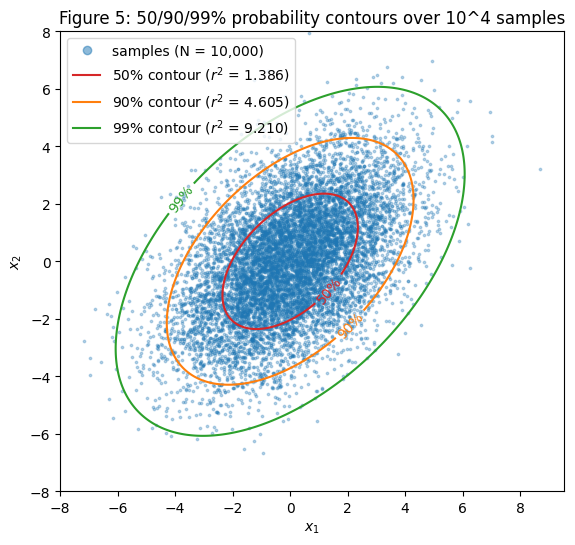


rho = 0.5000
eigenvalue 2.0000, eigenvector [-0.70710678  0.70710678], axis angle 135.0 deg, 1-sigma semi-axis 1.4142
   50% contour semi-axis: 1.6651
   90% contour semi-axis: 3.0349
   99% contour semi-axis: 4.2919
eigenvalue 6.0000, eigenvector [0.70710678 0.70710678], axis angle 45.0 deg, 1-sigma semi-axis 2.4495
   50% contour semi-axis: 2.8841
   90% contour semi-axis: 5.2565
   99% contour semi-axis: 7.4338

rho=0.0: det = 16.0000 (formula 16(1-rho^2) = 16.0000), Var(x2|x1) = 4.0000, 90% minor semi-axis = 4.2919
rho=0.5: det = 12.0000 (formula 16(1-rho^2) = 12.0000), Var(x2|x1) = 3.0000, 90% minor semi-axis = 3.0349
rho=0.9: det = 3.0400 (formula 16(1-rho^2) = 3.0400), Var(x2|x1) = 0.7600, 90% minor semi-axis = 1.3572
rho=0.99: det = 0.3184 (formula 16(1-rho^2) = 0.3184), Var(x2|x1) = 0.0796, 90% minor semi-axis = 0.4292


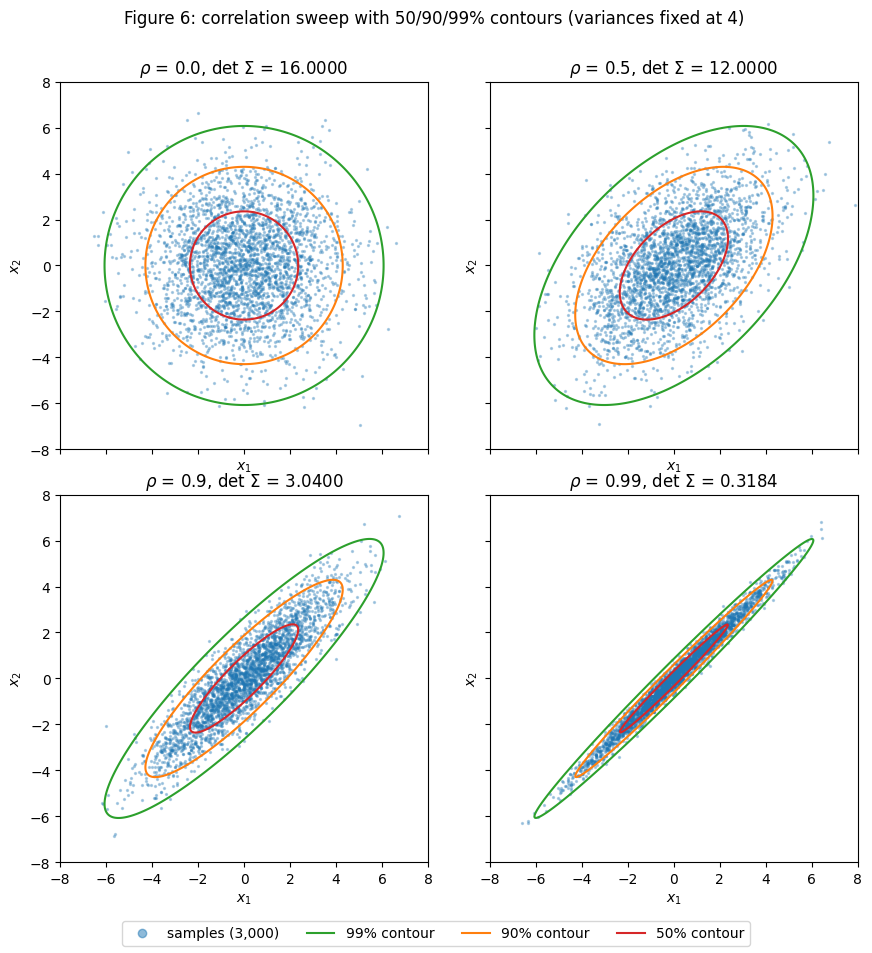

In [31]:
mu = np.zeros(2)
Sigma = np.array([[4.0, 2.0], [2.0, 4.0]])

# ---- check against scipy ----
check_pts = np.array([[0.0, 0.0], [1.0, -1.0], [2.5, 3.0], [-3.0, -2.0], [0.5, 4.0]])
pdf_mine = gaussian_pdf(check_pts, mu, Sigma)
pdf_scipy = multivariate_normal(mu, Sigma).pdf(check_pts)
max_rel_diff = (np.abs(pdf_mine - pdf_scipy) / pdf_scipy).max()
with np.printoptions(precision=8):
    print(f"mine  = {pdf_mine}")
    print(f"scipy = {pdf_scipy}")
print(f"largest relative difference = {max_rel_diff:.2e}")

# ---- normalization ----
L = 12.0
g = np.linspace(-L, L, 801)
GXn, GYn = np.meshgrid(g, g)
Zn = gaussian_pdf(np.dstack([GXn, GYn]), mu, Sigma)
integral = trap(trap(Zn, g, axis=1), g)
tail_bound = 4.0 * norm.sf(L / 2.0)
print(f"\nintegral over [-{L:.0f}, {L:.0f}]^2 with {g.size}x{g.size} grid = {integral:.10f}")
print(f"1 - integral = {1.0 - integral:.3e}")
print(f"upper bound on mass outside the square, 4 Q(6) = {tail_bound:.3e}")

# ---- probability contours ----
probs = [0.50, 0.90, 0.99]
r2_p = [-2.0 * np.log(1.0 - p) for p in probs]
det_Sigma = np.linalg.det(Sigma)
levels_p = [(1.0 - p) / (2.0 * np.pi * np.sqrt(det_Sigma)) for p in probs]

lam, V = np.linalg.eigh(Sigma)
for p, r2, lev in zip(probs, r2_p, levels_p):      # density at Mahalanobis radius r_p equals the level
    x_on = mu + np.sqrt(r2 * lam[-1]) * V[:, -1]
    assert np.isclose(gaussian_pdf(x_on, mu, Sigma), lev), "contour level mismatch"

N5 = 10**4
S5 = rng_step5.multivariate_normal(mu, Sigma, size=N5)
d2 = np.sum((S5 - mu).T * np.linalg.solve(Sigma, (S5 - mu).T), axis=0)

print(f"\ndet(Sigma) = {det_Sigma:.4f}")
for p, r2, lev in zip(probs, r2_p, levels_p):
    frac = np.mean(d2 <= r2)
    se = np.sqrt(p * (1.0 - p) / N5)
    print(f"p={p:.2f}: r^2={r2:.4f}  level={lev:.6f}  empirical={frac:.4f}  diff={frac - p:+.4f}  se={se:.4f}  z={(frac - p) / se:+.2f}")

# ---- Figure 5 ----
gg = np.linspace(-8, 8, 401)
GX, GY = np.meshgrid(gg, gg)
Zg = gaussian_pdf(np.dstack([GX, GY]), mu, Sigma)
order = np.argsort(levels_p)
colors = {0.50: "C3", 0.90: "C1", 0.99: "C2"}

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(S5[:, 0], S5[:, 1], s=3, alpha=0.3, color="C0")
cs = ax.contour(GX, GY, Zg, levels=[levels_p[i] for i in order], colors=[colors[probs[i]] for i in order])
ax.clabel(cs, fmt={levels_p[i]: f"{int(round(probs[i] * 100))}%" for i in order})
handles = [Line2D([], [], marker="o", ls="", color="C0", alpha=0.5, label=f"samples (N = {N5:,})")]
handles += [Line2D([], [], color=colors[p], label=f"{int(round(p * 100))}% contour ($r^2$ = {r2:.3f})") for p, r2 in zip(probs, r2_p)]
ax.legend(handles=handles, loc="upper left")
ax.set_aspect("equal")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title("Figure 5: 50/90/99% probability contours over 10^4 samples")
plt.show()

# ---- rho and ellipse axes ----
rho5 = Sigma[0, 1] / np.sqrt(Sigma[0, 0] * Sigma[1, 1])
print(f"\nrho = {rho5:.4f}")
for k in range(2):
    ang = np.degrees(np.arctan2(V[1, k], V[0, k])) % 180.0
    print(f"eigenvalue {lam[k]:.4f}, eigenvector {V[:, k]}, axis angle {ang:.1f} deg, 1-sigma semi-axis {np.sqrt(lam[k]):.4f}")
    for p, r2 in zip(probs, r2_p):
        print(f"   {int(round(p*100))}% contour semi-axis: {np.sqrt(lam[k] * r2):.4f}")

# ---- Figure 6: correlation sweep ----
rhos = [0.0, 0.5, 0.9, 0.99]
grid6 = np.dstack([GX, GY])
probs_desc = [0.99, 0.90, 0.50]
cols_desc = ["C2", "C1", "C3"]

fig, axes = plt.subplots(2, 2, figsize=(9, 9.6), sharex=True, sharey=True)
print()
for ax, r in zip(axes.ravel(), rhos):
    Sr = 4.0 * np.array([[1.0, r], [r, 1.0]])
    Sm = rng_step5.multivariate_normal(mu, Sr, size=3000)
    ax.scatter(Sm[:, 0], Sm[:, 1], s=2, alpha=0.3, color="C0")
    dr = np.linalg.det(Sr)
    lv = [(1.0 - p) / (2.0 * np.pi * np.sqrt(dr)) for p in probs_desc]
    ax.contour(GX, GY, gaussian_pdf(grid6, mu, Sr), levels=lv, colors=cols_desc)
    ax.set_title(rf"$\rho$ = {r}, det $\Sigma$ = {dr:.4f}")
    ax.set_aspect("equal")
    ax.set_xlim(-8, 8)
    ax.set_ylim(-8, 8)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    print(f"rho={r}: det = {dr:.4f} (formula 16(1-rho^2) = {16 * (1 - r**2):.4f}), "
          f"Var(x2|x1) = {4 * (1 - r**2):.4f}, 90% minor semi-axis = {np.sqrt(4.0 * (1.0 - r) * r2_p[1]):.4f}")
fig.suptitle("Figure 6: correlation sweep with 50/90/99% contours (variances fixed at 4)")
leg = [Line2D([], [], marker="o", ls="", color="C0", alpha=0.5, label="samples (3,000)")]
leg += [Line2D([], [], color=c, label=f"{int(round(p * 100))}% contour") for p, c in zip(probs_desc, cols_desc)]
fig.legend(handles=leg, loc="lower center", ncol=4)
plt.tight_layout(rect=(0, 0.04, 1, 0.97))
plt.show()

Figure 5 summary:
The samples form a tilted oval along x1 = x2, and the 50%, 90% and 99% contours are nested ellipses around them.
The positive correlation (rho = 0.5) is what tilts the ellipses toward the diagonal.

Fraction of samples inside the contours = [frac], [frac], [frac] (targets 0.50, 0.90, 0.99)
Largest deviation = [largest z from output] standard errors

The empirical fractions match the theoretical contour levels, so the levels from -2 ln(1 - p) are correct.

Figure 6 summary:
As rho increases from 0 to 0.99, the round cloud becomes a thin needle along x1 = x2.

det(Sigma) = 16.0000, 12.0000, 3.0400, 0.3184 for rho = 0, 0.5, 0.9, 0.99

As rho approaches 1, the determinant goes to 0 and the ellipse collapses onto a line.
The second measurement becomes almost completely determined by the first, so it adds very little new information.